# 42_edad_vs_color1

**Padre:** 22_word2vec_workers1

**Integrantes:** COMPLETAR

**CAMBIO 42:** `Age_Minus_Color1_Mean` = Age − edad promedio de las mascotas con su mismo Color1. **El promedio se calcula solo con train**: la regla del proyecto no deja usar test salvo para la entrega (el pedido decía train+test). No usa AdoptionSpeed.

Celdas tocadas: una celda nueva antes de la del CAMBIO 21. Todo lo demás igual que el 22.

**VALIDACIÓN:** folds `StratifiedGroupKFold` por `RescuerID`, semilla 42 (líneas `# CAMBIO VALIDACIÓN`).

# Este es el notebook final que genera la entrega, pueden hacer un fork de este notebook o iniciar uno propio; pero respetando los siguientes requisitos:

1. Generar una archivo de entrega válido, tal y como lo hace este. Para aprobar, el resultado debe ser superior a 0.3 (lo que da este)
2. Consignar los integrantes del grupo 
2. Puede tomar datos preprocesados en los mismos notebooks que este, en una modificación o en algo totalmente distinto
3. Es lícito tomar inspiración de los notebooks trabajados en clase y de los demás incluídos en mi perfil

### Si quieren consultar el resultado que van teniendo pueden hacerlo desde la pantalla de revisión del notebook, en la pestaña `DATA`, haciendo click en `submit` 

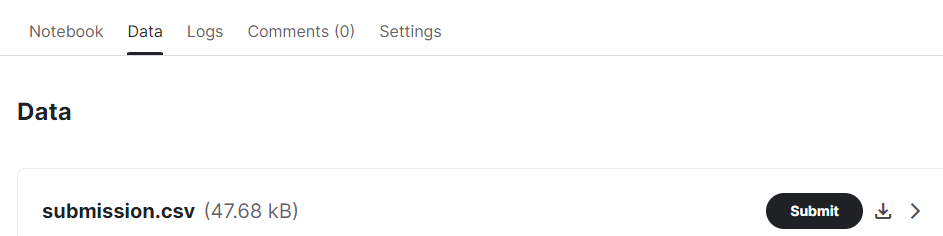

In [ ]:
# Importación de Librerías
import pandas as pd 

from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedGroupKFold   # CAMBIO VALIDACIÓN: folds por rescatista
from sklearn.metrics import cohen_kappa_score
from lightgbm import LGBMClassifier, early_stopping

def metric(y_true, y_pred):
    res = cohen_kappa_score(y_true, y_pred.reshape((y_true.shape[0], 5), order="F").argmax(axis=1), weights= 'quadratic')
    return "kappa", res, True

In [ ]:
# CAMBIO 01: librerías para regresión y para optimizar los umbrales
import numpy as np
from lightgbm import LGBMRegressor
from scipy.optimize import minimize

In [ ]:
train = pd.read_csv('../input/petfinder-adoption-prediction/train/train.csv').set_index("PetID")
test = pd.read_csv('../input/petfinder-adoption-prediction/test/test.csv').set_index("PetID")
# CAMBIO VALIDACIÓN: folds agrupados por rescatista (el mismo RescuerID nunca está en train y valid)
# y estratificados por AdoptionSpeed, semilla 42. Es la regla de validación del proyecto (Claude.md).
folds = [train.index[test_idx] for train_idx, test_idx in
         StratifiedGroupKFold(5, shuffle=True, random_state=42).split(train, train["AdoptionSpeed"], groups=train["RescuerID"])]
# folds = [train.index[test_idx] for train_idx, test_idx in KFold(5).split(train)]   # original

# CAMBIO VALIDACIÓN: si existe la copia local data/folds.csv, verificar que los folds son exactamente esos
import os
if os.path.exists("../data/folds.csv"):
    guardado = pd.read_csv("../data/folds.csv", index_col="PetID")["fold"]
    assert all((guardado.loc[f] == k).all() for k, f in enumerate(folds)), "Los folds no coinciden con data/folds.csv"
    print("Folds verificados contra data/folds.csv")

In [ ]:
for c in ['Type', 'Breed1', 'Breed2', 'Gender', 'Color1', 'Color2',
       'Color3', 'FurLength', 'MaturitySize', 'Vaccinated', 'Dewormed',
       'Sterilized', 'Health', 'State', 'RescuerID']:
    train[c] = train[c].astype("category")    
    test[c] = test[c].astype("category")

In [ ]:
# CAMBIO 02: cantidad de mascotas publicadas por cada rescatista.
# Cada conjunto se cuenta por separado: train con train, test con test (test solo se usa para la entrega).
# Ningún rescatista está en los dos conjuntos, así que es la cantidad total de publicaciones de ese rescatista.
train["RescuerID_count"] = train.groupby("RescuerID", observed=True)["RescuerID"].transform("size")
test["RescuerID_count"] = test.groupby("RescuerID", observed=True)["RescuerID"].transform("size")
print("Rescatistas en train y test a la vez:", len(set(train["RescuerID"]) & set(test["RescuerID"])))
train["RescuerID_count"].describe()

In [ ]:
# CAMBIO 04: puntaje medio de las etiquetas de Google Vision en la PRIMERA foto (una sola variable)
import glob, json, os

def score_primera_foto(carpeta):
    valores = {}
    for ruta in glob.glob(os.path.join(carpeta, "*-1.json")):      # solo "<PetID>-1.json"
        pet_id = os.path.basename(ruta)[:-len("-1.json")]
        with open(ruta, encoding="utf-8") as f:
            etiquetas = [e.get("score", 0) for e in json.load(f).get("labelAnnotations", [])]
        valores[pet_id] = np.mean(etiquetas) if etiquetas else np.nan
    return pd.Series(valores, name="meta1_label_score_mean")

train = train.join(score_primera_foto("../input/petfinder-adoption-prediction/train_metadata"))
test = test.join(score_primera_foto("../input/petfinder-adoption-prediction/test_metadata"))
print("Con valor: train", train["meta1_label_score_mean"].notna().mean().round(3),
      "| test", test["meta1_label_score_mean"].notna().mean().round(3))
train["meta1_label_score_mean"].describe()

In [ ]:
# CAMBIO 13 (bloque del 09): brillo, nitidez, aspecto y saturación de las fotos (OpenCV; ver prep_imagenes_opencv.ipynb)
train = train.join(pd.read_parquet("../input/lab2-prep-imagenes-opencv/train.parquet"))
test = test.join(pd.read_parquet("../input/lab2-prep-imagenes-opencv/test.parquet"))
print("Con fotos: train", train["img_cv_mean_brillo"].notna().mean().round(3),
      "| test", test["img_cv_mean_brillo"].notna().mean().round(3))
train.filter(like="img_cv_").describe().T.round(2)

In [ ]:
# CAMBIO 14 (bloque del 11): agregados por mascota de Google Vision (dominantColors, labelAnnotations, cropHints)
import glob, json, os
from joblib import Parallel, delayed

def valores_foto(ruta):
    # Devuelve listas de valores de UNA foto. Google omite los campos que valen 0, por eso el valor por defecto es 0.
    pet_id = os.path.basename(ruta)[:-len(".json")].rsplit("-", 1)[0]
    with open(ruta, encoding="utf-8") as f:
        m = json.load(f)
    colores = m.get("imagePropertiesAnnotation", {}).get("dominantColors", {}).get("colors", [])
    recortes = m.get("cropHintsAnnotation", {}).get("cropHints", [])
    return (pet_id,
            [c.get("score", 0) for c in colores],
            [c.get("pixelFraction", 0) for c in colores],
            [e.get("score", 0) for e in m.get("labelAnnotations", [])],
            [r.get("confidence", 0) for r in recortes],
            [r.get("importanceFraction", 0) for r in recortes])

def vision_por_mascota(carpeta):
    fotos = Parallel(n_jobs=-1, batch_size=512)(delayed(valores_foto)(r) for r in glob.glob(os.path.join(carpeta, "*.json")))
    nombres = ["dom_score", "dom_pixfrac", "label_score", "crop_conf", "crop_importance"]
    filas = []
    for pet_id, *listas in fotos:                     # una fila por valor individual
        for nombre, lista in zip(nombres, listas):
            filas += [(pet_id, nombre, v) for v in lista]
    largo = pd.DataFrame(filas, columns=["PetID", "variable", "valor"])
    agg = largo.groupby(["PetID", "variable"])["valor"].agg(["mean", "max"]).unstack("variable")
    agg.columns = [f"vis_{var}_{estad}" for estad, var in agg.columns]
    pedidas = ["vis_dom_score_mean", "vis_dom_score_max", "vis_dom_pixfrac_mean", "vis_dom_pixfrac_max",
               "vis_label_score_max",
               "vis_crop_conf_mean", "vis_crop_conf_max", "vis_crop_importance_mean", "vis_crop_importance_max"]
    return agg[pedidas]

train = train.join(vision_por_mascota("../input/petfinder-adoption-prediction/train_metadata"))
test = test.join(vision_por_mascota("../input/petfinder-adoption-prediction/test_metadata"))
print("Con metadata: train", train["vis_label_score_max"].notna().mean().round(3),
      "| test", test["vis_label_score_max"].notna().mean().round(3))
train.filter(like="vis_").describe().T.round(3)

In [ ]:
# CAMBIO 42: edad contra la edad promedio de su Color1 (promedio solo con train; no usa el target)
media_color = train.groupby("Color1", observed=True)["Age"].mean()
media_color.index = media_color.index.astype(int)
for df in (train, test):
    df["Age_Minus_Color1_Mean"] = df["Age"] - df["Color1"].astype(int).map(media_color)
print(media_color.round(1).to_dict())

In [ ]:
# CAMBIO 21: Word2Vec sobre Description, entrenado SOLO con el train de cada fold
# (en Kaggle gensim viene instalado; si no, hace falta internet para instalarlo)
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

# Tokens guardados aparte: más abajo select_dtypes saca la columna de texto de train/test
tokens_train = train["Description"].fillna("").astype(str).map(simple_preprocess)
tokens_test = test["Description"].fillna("").astype(str).map(simple_preprocess)
print("Descripciones sin ninguna palabra: train", (tokens_train.str.len() == 0).sum(), "| test", (tokens_test.str.len() == 0).sum())

W2V_DIM = 100

import zlib
def hash_fijo(texto):   # CAMBIO 22: el hash de Python cambia en cada proceso; crc32 no
    return zlib.crc32(texto.encode("utf-8"))
W2V_COLS = [f"w2v_{k}" for k in range(W2V_DIM)]

def vector_promedio(tokens, modelo):
    conocidas = [t for t in tokens if t in modelo.wv.key_to_index]
    return modelo.wv[conocidas].mean(axis=0) if conocidas else np.zeros(W2V_DIM)

def agregar_w2v(X_tr, X_va, X_te, tok_tr, tok_va, tok_te):
    # CAMBIO 22: workers=1 y hashfxn fijo -> mismo resultado en cada corrida
    modelo = Word2Vec(sentences=list(tok_tr), vector_size=W2V_DIM, window=5, min_count=2, workers=1, seed=42,
                      hashfxn=hash_fijo)
    # modelo = Word2Vec(sentences=list(tok_tr), vector_size=W2V_DIM, window=5, min_count=2, workers=4, seed=42)   # 21
    salida = []
    for X, tok in ((X_tr, tok_tr), (X_va, tok_va), (X_te, tok_te)):
        vectores = pd.DataFrame(np.vstack([vector_promedio(t, modelo) for t in tok]), index=X.index, columns=W2V_COLS)
        salida.append(pd.concat([X, vectores], axis=1))
    return salida, len(modelo.wv)

In [ ]:
train = train\
    .join(pd.read_parquet("../input/examen-lab-ii-preprocesado-texto/train.parquet"))\
    .join(pd.read_parquet("../input/examen-lab-ii-preprocesado-img/train.parquet"))\
    .select_dtypes(exclude="O")
train

In [ ]:
test = test\
    .join(pd.read_parquet("../input/examen-lab-ii-preprocesado-texto/test.parquet"))\
    .join(pd.read_parquet("../input/examen-lab-ii-preprocesado-img/test.parquet"))\
    .select_dtypes(exclude="O")
test

In [ ]:
# CAMBIO 12: semillas a promediar en cada fold
SEMILLAS = [0, 1, 2, 3, 4]

fold_preds = []
test_preds = []
for i, fold in enumerate(folds):
    X_train = train.drop(fold).drop("AdoptionSpeed", axis=1).select_dtypes(exclude="O")
    y_train = train.drop(fold)["AdoptionSpeed"]

    X_valid = train.loc[fold].drop("AdoptionSpeed", axis=1).select_dtypes(exclude="O")
    y_valid = train.loc[fold, "AdoptionSpeed"]

    # CAMBIO 21: Word2Vec entrenado con las descripciones del train de este fold; vectores para train, valid y test
    (X_train, X_valid, X_test), vocabulario = agregar_w2v(
        X_train, X_valid, test[X_train.columns],
        tokens_train.loc[X_train.index], tokens_train.loc[X_valid.index], tokens_test.loc[test.index])
    print(f"fold {i}: vocabulario Word2Vec", vocabulario, "palabras")

    # CAMBIO 12: un modelo por semilla, con 80% de filas y columnas al azar; se promedian las predicciones
    pred_valid, pred_test, iteraciones = [], [], []
    for semilla in SEMILLAS:
        learner = LGBMRegressor(random_state=semilla, subsample=0.8, subsample_freq=1, colsample_bytree=0.8)
        # learner = LGBMRegressor()   # 04 (CAMBIO 01)
        # learner.fit(X_train, y_train, )   # CAMBIO 12: quitado; el fit siguiente lo reemplazaba (no cambia resultados)

        # CAMBIO 01: sin eval_metric=metric (esa función es para 5 probabilidades);
        # el early stopping usa el error cuadrático (l2) de la regresión
        learner.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_valid, y_valid)],
                    callbacks=[early_stopping(5, verbose=False)])
        iteraciones.append(learner.best_iteration_)   # CAMBIO 13: guardar la iteración de cada semilla
        pred_valid.append(learner.predict(X_valid))
        pred_test.append(learner.predict(X_test[X_train.columns]))   # CAMBIO 21: test con los vectores de este fold
        # pred_test.append(learner.predict(test[X_train.columns]))   # 14
    print(f"fold {i}: mejores iteraciones por semilla", iteraciones)   # CAMBIO 13: antes mostraba solo la última
    fold_preds.append(pd.Series(np.mean(pred_valid, axis=0), index=fold, name="AdoptionSpeed"))
    test_preds.append(pd.Series(np.mean(pred_test, axis=0), index=test.index))
    # fold_preds.append(pd.Series(learner.predict(X_valid), index=fold, name="AdoptionSpeed"))   # 04
    # test_preds.append(pd.Series(learner.predict(test[X_train.columns]), index=test.index))     # 04

fold_preds = pd.concat(fold_preds)
# CAMBIO 01: promedio de los 5 modelos; los umbrales se aplican en la celda siguiente
test_preds = sum(test_preds) / len(test_preds)

In [ ]:
# CAMBIO 01: umbrales optimizados para pasar del número continuo a la clase 0-4
def aplicar_cortes(pred, cortes):
    # 3 cortes ordenados -> clases 0..4 (debajo del 1er corte = 0, encima del 4to = 4)
    return np.digitize(pred, np.sort(cortes))

def optimizar_cortes(pred, y, inicio=(0.5, 1.5, 2.5, 3.5)):
    perdida = lambda c: -cohen_kappa_score(y, aplicar_cortes(pred, c), weights="quadratic")
    return np.sort(minimize(perdida, inicio, method="nelder-mead").x)

y_oof = train.loc[fold_preds.index, "AdoptionSpeed"]

# MEDICIÓN honesta: los cortes de cada fold se eligen con los OTROS 4 folds
# (si se eligen con todos, el kappa sale inflado porque los cortes 'vieron' las respuestas)
oof_clases = []
for fold in folds:
    resto = fold_preds.index.difference(fold)
    c = optimizar_cortes(fold_preds[resto], y_oof[resto])
    oof_clases.append(pd.Series(aplicar_cortes(fold_preds[fold], c), index=fold))
oof_clases = pd.concat(oof_clases)
kappa_oof = cohen_kappa_score(y_oof[oof_clases.index], oof_clases, weights="quadratic")

# Para la entrega: cortes elegidos con TODO el OOF
cortes = optimizar_cortes(fold_preds, y_oof)
kappa_optimista = cohen_kappa_score(y_oof, aplicar_cortes(fold_preds, cortes), weights="quadratic")
print("Cortes:", np.round(cortes, 3))
print(f"Kappa OOF (honesto, el que se compara): {kappa_oof:.4f}")
print(f"Kappa OOF (optimista, solo referencia):  {kappa_optimista:.4f}")

test_preds = pd.Series(aplicar_cortes(test_preds, cortes), index=test_preds.index, name="AdoptionSpeed")
test_preds.value_counts().sort_index()

In [ ]:
# MEDICIÓN (no cambia la entrega): kappa por fold, media ± desvío, y guardado para comparar
import json
pred_clase = oof_clases if "oof_clases" in globals() else fold_preds
kappas = [cohen_kappa_score(train.loc[f, "AdoptionSpeed"], pred_clase[f], weights="quadratic") for f in folds]
kappa_total = cohen_kappa_score(train.loc[pred_clase.index, "AdoptionSpeed"], pred_clase, weights="quadratic")
print("Kappa por fold:", [round(k, 4) for k in kappas])
print(f"Kappa media: {pd.Series(kappas).mean():.4f} ± {pd.Series(kappas).std():.4f}   |   Kappa OOF total: {kappa_total:.4f}")
json.dump({"notebook": "42_edad_vs_color1", "kappas_fold": kappas, "kappa_total": kappa_total},
          open("resultados_42_edad_vs_color1.json", "w"))

In [ ]:
test_preds.to_csv("submission.csv")
!head submission.csv